# GPP case: sampling × model R², SHAP time, distance to a reference explanation

Y is FluxCom GPP. X is ERA5 VPD / t2m / ssrd, ESA CCI SM, and GPCP precipitation, already on the ERA5 1° grid. Time is stamped to `YYYY-MM-01` and inner-joined (2001–2013).

1. Load cubes and flatten valid land cells.
2. Sampling methods and sample sizes.
3. Models.
4. Test-set R² for every (n, method, model).
5. SHAP wall time and dependence-curve distance to a **reference** explanation (`extra_trees` + `random` + largest n), using `compare_explanations`.

Do not execute this notebook until you are ready; the grid can take a while.

In [1]:
from pathlib import Path
import sys
import time

root = Path.cwd().resolve()
if not (root / "src" / "rf_shap").exists() and (root.parent / "src" / "rf_shap").exists():
    root = root.parent
if str(root / "src") not in sys.path:
    sys.path.insert(0, str(root / "src"))
fastforest_root = Path("/Users/huangfeini/Documents/FastForest")
if fastforest_root.exists() and str(fastforest_root) not in sys.path:
    sys.path.insert(0, str(fastforest_root))

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

from rf_shap.cube.align import stamp_year_month
from rf_shap.cube.tabular import SampleTable, cube_to_table
from rf_shap.explain.evaluate import compare_explanations
from rf_shap.explain.shap_explain import compute_shap
from rf_shap.models.registry import available_models, build_model
from rf_shap.models.sampling import sample_train
from rf_shap.models.split import time_split
from rf_shap.predict.metrics import regression_metrics

print("models:", available_models())

models: ['rf', 'extra_trees', 'hist_gbm', 'xgboost', 'lightgbm', 'lightgbm_rf', 'fastforest']


## 1. Read inputs (X) and output (Y)

Aligned GPP / SM / PR live in `vpd_gpp_1deg/obs`. ERA5 drivers use the same 1° coordinates; `valid_time` is renamed and stamped to month start so the join is exact.

In [2]:
OBS = Path("/Users/huangfeini/Documents/esm_case_data/vpd_gpp_1deg/obs")
ERA5 = {
    "vpd": "era5_monthly_1deg_1980-2014_vapour_pressure_deficit.nc",
    "t2m": "era5_monthly_1deg_1980-2014_2m_temperature.nc",
    "ssrd": "era5_monthly_1deg_1980-2014_surface_solar_radiation_downwards.nc",
}
FEATURES = ["vpd", "t2m", "ssrd", "sm", "pr"]
TARGET = "gpp"
SEED = 42

def open_cube(path, rename=None):
    ds = xr.open_dataset(path)
    mapping = {}
    for src, dst in (("valid_time", "time"), ("latitude", "lat"), ("longitude", "lon")):
        if src in ds.dims or src in ds.coords:
            mapping[src] = dst
    if mapping:
        ds = ds.rename(mapping)
    ds = stamp_year_month(ds)
    extra = [d for d in ds.dims if d not in ("time", "lat", "lon")]
    if extra:
        ds = ds.isel({d: 0 for d in extra})
    if rename:
        data_name = rename if rename in ds.data_vars else list(ds.data_vars)[0]
        ds = ds[[data_name]].rename({data_name: rename})
    return ds

aligned = open_cube(OBS / "aligned_gpp_sm_pr_monthly_1deg_2001-2013.nc")
era5 = {name: open_cube(OBS / fname, rename=name) for name, fname in ERA5.items()}
x = xr.merge([era5["vpd"], era5["t2m"], era5["ssrd"], aligned[["sm", "pr"]]])
y = aligned[[TARGET]]
x, y = xr.align(x, y, join="inner")
print("X", dict(x.sizes), list(x.data_vars))
print("Y", dict(y.sizes), list(y.data_vars))
print("time", pd.to_datetime(x.time.values[0]), "→", pd.to_datetime(x.time.values[-1]))
display(x)
display(y)

/var/folders/dt/kjt_y18n1hg0cl9bgjvs5_b80000gn/T/ipykernel_76025/1003422324.py:30: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'time' ('time',) The recommendation is to set join explicitly for this case.
  x = xr.merge([era5["vpd"], era5["t2m"], era5["ssrd"], aligned[["sm", "pr"]]])


X {'lat': 181, 'lon': 360, 'time': 156} ['vpd', 't2m', 'ssrd', 'sm', 'pr']
Y {'lat': 181, 'lon': 360, 'time': 156} ['gpp']
time 2001-01-01 00:00:00 → 2013-12-01 00:00:00


<xarray.Dataset> Size: 203MB
Dimensions:  (lat: 181, lon: 360, time: 156)
Coordinates:
  * lat      (lat) float64 1kB 90.0 89.0 88.0 87.0 ... -87.0 -88.0 -89.0 -90.0
  * lon      (lon) float64 3kB 0.0 1.0 2.0 3.0 4.0 ... 356.0 357.0 358.0 359.0
  * time     (time) datetime64[ns] 1kB 2001-01-01 2001-02-01 ... 2013-12-01
Data variables:
    vpd      (time, lat, lon) float32 41MB ...
    t2m      (time, lat, lon) float32 41MB ...
    ssrd     (time, lat, lon) float32 41MB ...
    sm       (time, lat, lon) float32 41MB nan nan nan nan ... nan nan nan nan
    pr       (time, lat, lon) float32 41MB 0.5225 0.6433 0.6974 ... nan nan nan
Attributes:
    regrid:         area-weighted 1 degree
    regrid_grid:    era5
    regrid_source:  /Users/huangfeini/Documents/esm_case_data/obs/era5_monthl...

<xarray.Dataset> Size: 41MB
Dimensions:  (lat: 181, lon: 360, time: 156)
Coordinates:
  * lat      (lat) float64 1kB 90.0 89.0 88.0 87.0 ... -87.0 -88.0 -89.0 -90.0
  * lon      (lon) float64 3kB 0.0 1.0 2.0 3.0 4.0 ... 356.0 357.0 358.0 359.0
  * time     (time) datetime64[ns] 1kB 2001-01-01 2001-02-01 ... 2013-12-01
Data variables:
    gpp      (time, lat, lon) float32 41MB ...
Attributes:
    comment:        Inner join on year-month after area-weighted remap onto t...
    time_coverage:  overlap of FluxCom GPP, ESA CCI SM, and GPCP (2001-01 to ...

In [5]:
x['pr'].shape

(156, 181, 360)

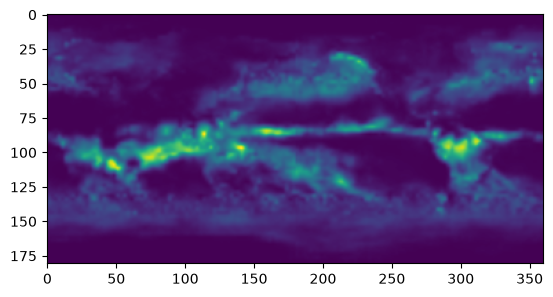

In [6]:
plt.imshow(x['pr'].values[0,:,:])

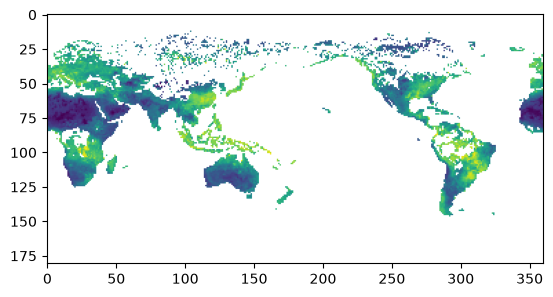

In [8]:
plt.imshow(x['sm'].values[0,:,:])

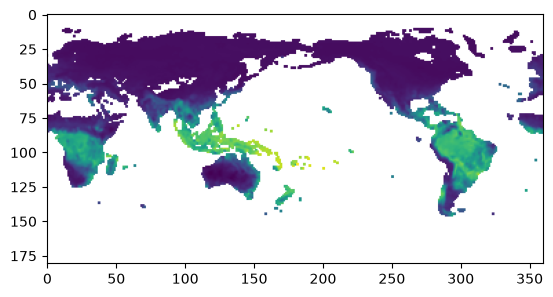

In [9]:
plt.imshow(y['gpp'].values[0,:,:])

In [10]:
table = cube_to_table(x[FEATURES], y, y_name=TARGET)
print("valid cells", table.n_samples, "of", table.extras["n_raw"], "features", table.feature_names)
split = time_split(table, test_size=0.2)
train_pool, test = split.train, split.test
print("train pool", train_pool.n_samples, "test", test.n_samples, "cutoff", split.extras.get("cutoff"))
lat_pool = np.asarray(train_pool.index.get_level_values("lat"))
lon_pool = np.asarray(train_pool.index.get_level_values("lon"))
time_pool = np.asarray(train_pool.index.get_level_values("time"))

valid cells 1828980 of 10164960 features ['vpd', 't2m', 'ssrd', 'sm', 'pr']
train pool 1461384 test 367596 cutoff 2011-04-01 00:00:00


## 2. Sampling methods and sample sizes

Sampling only happens inside the chronological training pool. The test set is fixed.

In [12]:
SAMPLE_SIZES = [200, 500, 1000, 2000,10000]
SAMPLE_METHODS = [
    "random",
    "stratified",
    "systematic",
    "area",
    "process",
    "fscs",
    "cluster_medoid",
    "spatial",
    "kennard_stone",
    "maximin",
    "clhs",
    "aclhs",
    "extreme",
    "active",
]

def draw_train(method, n_samples):
    t0 = time.perf_counter()
    idx = sample_train(
        train_pool.X,
        train_pool.y,
        method=method,
        n_samples=n_samples,
        seed=SEED,
        lat=lat_pool,
        lon=lon_pool,
        time=time_pool,
    )
    return train_pool.take(idx), float(time.perf_counter() - t0)

print("n_samples", SAMPLE_SIZES)
print("methods", SAMPLE_METHODS)

n_samples [200, 500, 1000, 2000, 10000]
methods ['random', 'stratified', 'systematic', 'area', 'process', 'fscs', 'cluster_medoid', 'spatial', 'kennard_stone', 'maximin', 'clhs', 'aclhs', 'extreme', 'active']


## 3. Models

Only backends that import successfully are kept. TreeSHAP-style explainers work on RF / ExtraTrees / XGBoost / LightGBM; `fastforest` is skipped for SHAP if it does not support TreeSHAP.

In [14]:
MODEL_SPECS = [
    ("extra_trees", {"n_estimators": 80, "max_depth": 12, "n_jobs": -1}),
    ("rf", {"n_estimators": 80, "max_depth": 12, "n_jobs": -1}),
    ("hist_gbm", {"max_iter": 120, "max_depth": 8}),
    ("xgboost", {"n_estimators": 120, "max_depth": 8, "n_jobs": -1}),
    ("lightgbm", {"n_estimators": 120, "max_depth": 8, "n_jobs": -1}),
    ("lightgbm_rf", {"n_estimators": 120, "max_depth": 12, "n_jobs": -1}),
]
installed = set(available_models())
MODEL_SPECS = [(name, params) for name, params in MODEL_SPECS if name in installed]
print("using models", [name for name, _ in MODEL_SPECS])

def fit_score(model_name, params, train_table):
    model = build_model(model_name, params, seed=SEED)
    t0 = time.perf_counter()
    model.fit(train_table.X, train_table.y)
    fit_s = float(time.perf_counter() - t0)
    pred = model.predict(test.X)
    metrics = regression_metrics(test.y, pred)
    metrics["fit_s"] = fit_s
    metrics["n_train"] = int(len(train_table.y))
    return model, metrics

using models ['extra_trees', 'rf', 'hist_gbm', 'xgboost', 'lightgbm', 'lightgbm_rf']


## 4. R² for sample size × sampling method × model

In [15]:
skill_rows = []
fitted = {}  # (n, method, model) -> (model, train_table)
for n_samples in SAMPLE_SIZES:
    for method in SAMPLE_METHODS:
        try:
            train_table, sample_s = draw_train(method, n_samples)
        except Exception as exc:
            print("skip sample", method, n_samples, type(exc).__name__, exc)
            continue
        for model_name, params in MODEL_SPECS:
            model, metrics = fit_score(model_name, params, train_table)
            fitted[(n_samples, method, model_name)] = (model, train_table)
            skill_rows.append({
                "n_samples": n_samples,
                "method": method,
                "model": model_name,
                "sample_s": sample_s,
                **metrics,
            })
            print(n_samples, method, model_name, "R2", round(metrics["r2"], 3))

skill = pd.DataFrame(skill_rows)
display(skill[["n_samples", "method", "model", "n_train", "r2", "rmse", "ubrmse", "sample_s", "fit_s"]])
r2_table = skill.pivot_table(index=["method", "n_samples"], columns="model", values="r2")
display(r2_table)

200 random extra_trees R2 0.718
200 random rf R2 0.684
200 random hist_gbm R2 0.712
200 random xgboost R2 0.617
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000330 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 340
[LightGBM] [Info] Number of data points in the train set: 200, number of used features: 5
[LightGBM] [Info] Start training from score 2.181355
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further spli

,n_samples,method,model,n_train,r2,rmse,ubrmse,sample_s,fit_s
0,200,random,extra_trees,200,0.718317,1.241850,1.230380,0.007590,0.115812
1,200,random,rf,200,0.683511,1.316340,1.301844,0.007590,0.046778
2,200,random,hist_gbm,200,0.712048,1.255591,1.243311,0.007590,0.240985
3,200,random,xgboost,200,0.616682,1.448666,1.444274,0.007590,0.144686
4,200,random,lightgbm,200,0.714156,1.250989,1.235544,0.007590,0.074619
...,...,...,...,...,...,...,...,...,...
415,10000,active,rf,10000,0.782778,1.090537,1.081334,8.194256,0.221664
416,10000,active,hist_gbm,10000,0.783586,1.088506,1.073742,8.194256,0.972680
417,10000,active,xgboost,10000,0.786266,1.081745,1.070194,8.194256,0.219928
418,10000,active,lightgbm,10000,0.784476,1.086265,1.072053,8.194256,0.242050


model                 extra_trees  hist_gbm  lightgbm  lightgbm_rf        rf  \
method     n_samples                                                           
aclhs      200           0.740654  0.733346  0.725409     0.658378  0.734090   
           500           0.755149  0.719567  0.715401     0.685483  0.735139   
           1000          0.765140  0.760938  0.758498     0.734327  0.761629   
           2000          0.781097  0.774517  0.774949     0.753805  0.781612   
           10000         0.787549  0.799374  0.798821     0.748464  0.797632   
...                           ...       ...       ...          ...       ...   
systematic 200           0.688491  0.700524  0.702237     0.570992  0.675290   
           500           0.758432  0.749792  0.747509     0.715204  0.753534   
           1000          0.771926  0.762974  0.760155     0.731890  0.765074   
           2000          0.778087  0.778078  0.777216     0.747885  0.777644   
           10000         0.786398  0.797573  0.798292     0.748960  0.795357   

model                  xgboost  
method     n_samples            
aclhs      200        0.679545  
           500        0.689784  
           1000       0.744596  
           2000       0.766972  
           10000      0.794833  
...                        ...  
systematic 200        0.635992  
           500        0.728956  
           1000       0.744549  
           2000       0.761861  
           10000      0.796260  

[70 rows x 6 columns]

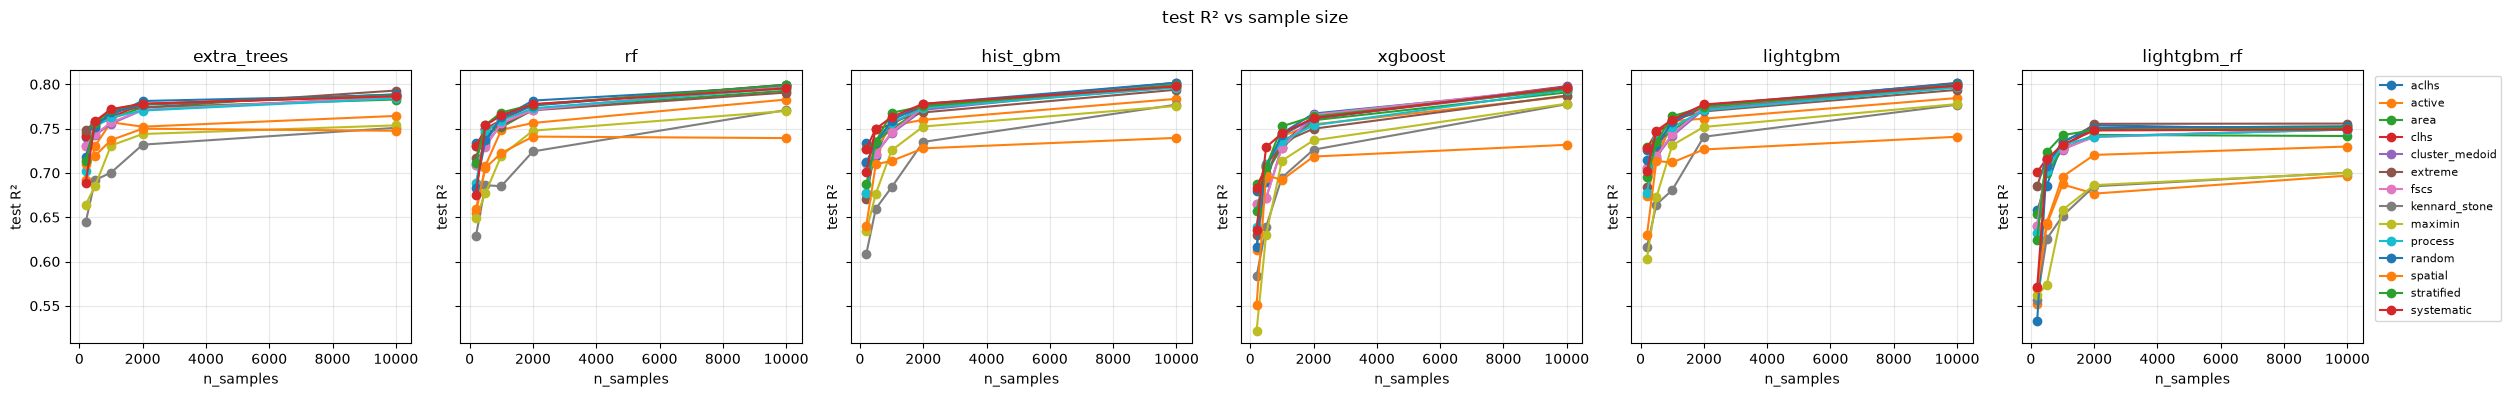

In [16]:
fig, axes = plt.subplots(1, len(MODEL_SPECS), figsize=(4.2 * max(len(MODEL_SPECS), 1), 4.0), sharey=True, squeeze=False)
for ax, (model_name, _) in zip(axes[0], MODEL_SPECS):
    sub = skill[skill["model"] == model_name]
    for method, group in sub.groupby("method"):
        ax.plot(group["n_samples"], group["r2"], marker="o", label=method)
    ax.set_title(model_name)
    ax.set_xlabel("n_samples")
    ax.set_ylabel("test R²")
    ax.grid(True, alpha=0.3)
axes[0][-1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
fig.suptitle("test R² vs sample size")
fig.tight_layout()
plt.show()

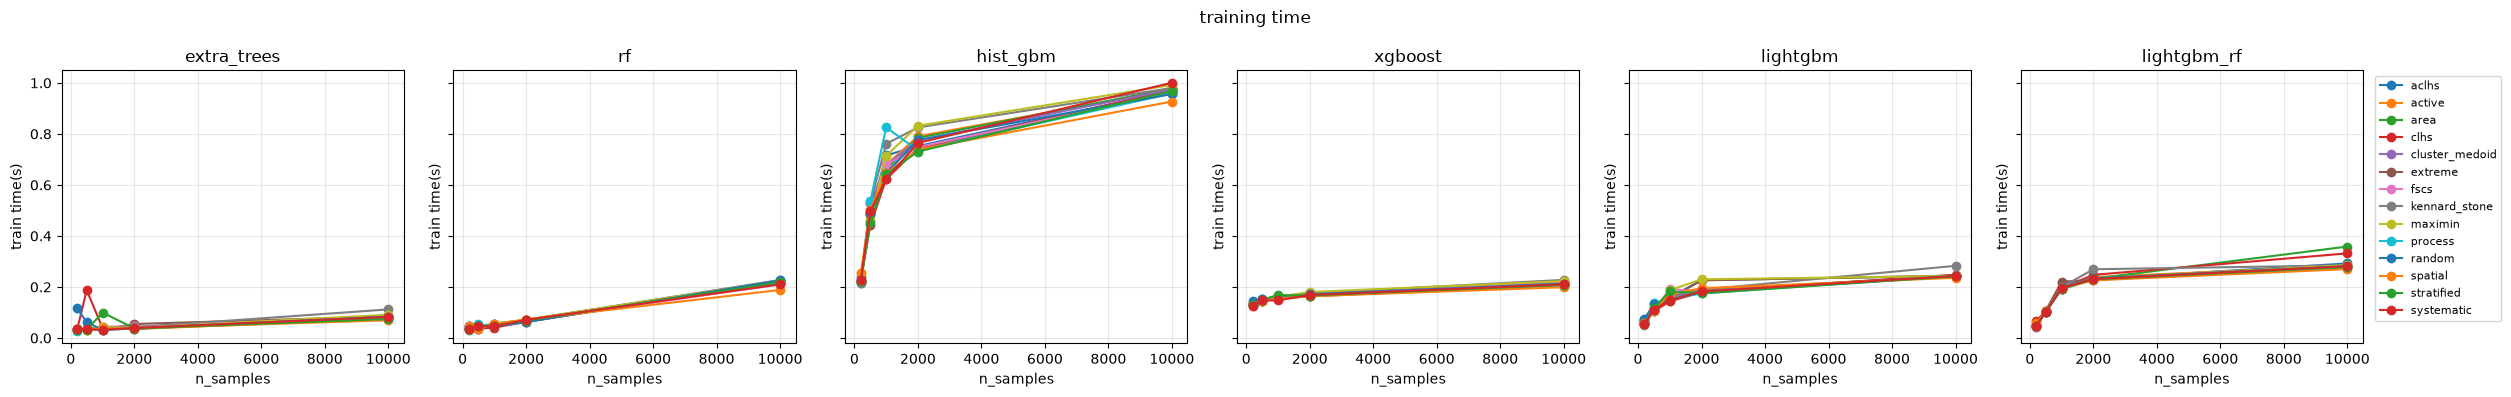

In [20]:
fig, axes = plt.subplots(1, len(MODEL_SPECS), figsize=(4.2 * max(len(MODEL_SPECS), 1), 4.0), sharey=True, squeeze=False)
for ax, (model_name, _) in zip(axes[0], MODEL_SPECS):
    sub = skill[skill["model"] == model_name]
    for method, group in sub.groupby("method"):
        ax.plot(group["n_samples"], group["fit_s"], marker="o", label=method)
    ax.set_title(model_name)
    ax.set_xlabel("n_samples")
    ax.set_ylabel("train time(s)")
    ax.grid(True, alpha=0.3)
axes[0][-1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
fig.suptitle("training time")
fig.tight_layout()
plt.show()

In [19]:
skill

,n_samples,method,model,sample_s,n,r2,rmse,mae,bias,ubrmse,nse,kge,pearson_r,mape,fit_s,n_train
0,200,random,extra_trees,0.007590,367596,0.718317,1.241850,0.875202,-0.168393,1.230380,0.718317,0.743492,0.852176,9.358446,0.115812,200
1,200,random,rf,0.007590,367596,0.683511,1.316340,0.934011,-0.194814,1.301844,0.683511,0.719451,0.832129,8.425198,0.046778,200
2,200,random,hist_gbm,0.007590,367596,0.712048,1.255591,0.900663,-0.175177,1.243311,0.712048,0.759168,0.847424,7.128898,0.240985,200
3,200,random,xgboost,0.007590,367596,0.616682,1.448666,1.017534,-0.112723,1.444274,0.616682,0.761156,0.792671,16.684437,0.144686,200
4,200,random,lightgbm,0.007590,367596,0.714156,1.250989,0.893227,-0.195969,1.235544,0.714156,0.759364,0.849509,7.118066,0.074619,200
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
415,10000,active,rf,8.194256,367596,0.782778,1.090537,0.756430,-0.141373,1.081334,0.782778,0.790361,0.888720,5.078255,0.221664,10000
416,10000,active,hist_gbm,8.194256,367596,0.783586,1.088506,0.751479,-0.178675,1.073742,0.783586,0.799263,0.889538,6.539778,0.972680,10000
417,10000,active,xgboost,8.194256,367596,0.786266,1.081745,0.743846,-0.157665,1.070194,0.786266,0.811469,0.889809,4.435943,0.219928,10000
418,10000,active,lightgbm,8.194256,367596,0.784476,1.086265,0.750369,-0.175140,1.072053,0.784476,0.801395,0.889829,5.284733,0.242050,10000


In [18]:
skill.to_csv('skill.csv')

## 5. SHAP time and distance to the reference explanation

Reference: `extra_trees` + `random` + largest `n_samples`. Every run explains the **same** test subset so `compare_explanations` / `dependence_curve_distance` is on the same X. Distance is the mean feature-wise dependence-SHAP curve distance to that reference.

In [21]:
N_EXPLAIN = 400
SHAP_METHOD = "auto"
REF_MODEL = "extra_trees"
REF_METHOD = "random"
REF_N = max(SAMPLE_SIZES)
explain_table = test.take(np.arange(min(N_EXPLAIN, test.n_samples)))

def shap_on_test(model, background):
    t0 = time.perf_counter()
    result = compute_shap(
        model,
        explain_table,
        method=SHAP_METHOD,
        max_samples=None,
        background_size=80,
        background=background,
        seed=SEED,
    )
    elapsed = float(time.perf_counter() - t0)
    return result, elapsed

ref_key = (REF_N, REF_METHOD, REF_MODEL)
if ref_key not in fitted:
    raise KeyError(f"reference {ref_key} was not fitted; check MODEL_SPECS / SAMPLE_METHODS")
ref_model, ref_train = fitted[ref_key]
ref_shap, ref_time = shap_on_test(ref_model, ref_train.X)
x_ref = explain_table.X[ref_shap.sample_positions]
print("reference", ref_key, "explain_s", round(ref_time, 3), "method", ref_shap.method)

shap_rows = []
for (n_samples, method, model_name), (model, train_table) in fitted.items():
    try:
        shap_res, explain_s = shap_on_test(model, train_table.X)
        x_other = explain_table.X[shap_res.sample_positions]
        compared = compare_explanations(
            x_ref=x_ref,
            shap_ref=ref_shap.values,
            x_other=x_other,
            shap_other=shap_res.values,
            feature_names=explain_table.feature_names,
        )
        dist = compared["dependence_distance"]["distance"]
        slope = compared["slope_difference"]["difference"].abs()
        shap_rows.append({
            "n_samples": n_samples,
            "method": method,
            "model": model_name,
            "explain_s": explain_s,
            "explain_method": shap_res.method,
            "shap_distance": float(dist.mean()),
            "shap_distance_max": float(dist.max()),
            "slope_abs_diff": float(slope.mean()),
            "is_reference": (n_samples, method, model_name) == ref_key,
        })
        print(n_samples, method, model_name, "explain_s", round(explain_s, 3), "dist", round(float(dist.mean()), 4))
    except Exception as exc:
        print("skip shap", n_samples, method, model_name, type(exc).__name__, exc)

shap_skill = pd.DataFrame(shap_rows)
display(shap_skill)
time_table = shap_skill.pivot_table(index=["method", "n_samples"], columns="model", values="explain_s")
dist_table = shap_skill.pivot_table(index=["method", "n_samples"], columns="model", values="shap_distance")
print("SHAP time (s)")
display(time_table)
print("mean dependence-SHAP distance to reference")
display(dist_table)

IPython could not be loaded!


reference (10000, 'random', 'extra_trees') explain_s 0.827 method fasttreeshap
200 random extra_trees explain_s 0.021 dist 0.1771
200 random rf explain_s 0.011 dist 0.2883
200 random hist_gbm explain_s 0.01 dist 0.1711
skip shap 200 random xgboost UnicodeDecodeError 'utf-8' codec can't decode byte 0x89 in position 815: invalid start byte
200 random lightgbm explain_s 0.015 dist 0.1746
200 random lightgbm_rf explain_s 0.012 dist 44.2477
200 stratified extra_trees explain_s 0.019 dist 0.2111
200 stratified rf explain_s 0.01 dist 0.2091
200 stratified hist_gbm explain_s 0.011 dist 0.2665
skip shap 200 stratified xgboost UnicodeDecodeError 'utf-8' codec can't decode byte 0xb3 in position 814: invalid start byte
200 stratified lightgbm explain_s 0.012 dist 0.2634
200 stratified lightgbm_rf explain_s 0.01 dist 45.1872
200 systematic extra_trees explain_s 0.02 dist 0.2044
200 systematic rf explain_s 0.01 dist 0.2083
200 systematic hist_gbm explain_s 0.011 dist 0.1761
skip shap 200 systematic 

,n_samples,method,model,explain_s,explain_method,shap_distance,shap_distance_max,slope_abs_diff,is_reference
0,200,random,extra_trees,0.020504,fasttreeshap,0.177140,0.566002,0.577892,False
1,200,random,rf,0.011441,fasttreeshap,0.288294,0.692488,0.824814,False
2,200,random,hist_gbm,0.009764,fasttreeshap,0.171143,0.276615,0.211145,False
3,200,random,lightgbm,0.014787,fasttreeshap,0.174604,0.279062,0.229474,False
4,200,random,lightgbm_rf,0.011503,fasttreeshap,44.247670,95.599351,94.038260,False
...,...,...,...,...,...,...,...,...,...
345,10000,active,extra_trees,0.353405,fasttreeshap,0.153416,0.254361,0.554008,False
346,10000,active,rf,0.333125,fasttreeshap,0.260551,0.474063,0.794621,False
347,10000,active,hist_gbm,0.035116,fasttreeshap,0.262023,0.474546,0.518307,False
348,10000,active,lightgbm,0.061470,fasttreeshap,0.265656,0.480598,0.523942,False


SHAP time (s)


model                 extra_trees  hist_gbm  lightgbm  lightgbm_rf        rf
method     n_samples                                                        
aclhs      200           0.019622  0.010377  0.011953     0.009503  0.010624
           500           0.048660  0.020155  0.023079     0.021500  0.032961
           1000          0.136745  0.023961  0.035092     0.057645  0.060608
           2000          0.162129  0.029161  0.051849     0.098348  0.111190
           10000         0.435237  0.036080  0.062615     0.063063  0.369875
...                           ...       ...       ...          ...       ...
systematic 200           0.019625  0.010695  0.012099     0.009549  0.009743
           500           0.046872  0.020790  0.024232     0.024124  0.029153
           1000          0.096953  0.023212  0.031657     0.062782  0.056624
           2000          0.180264  0.028136  0.055069     0.061216  0.135283
           10000         0.379761  0.035102  0.061695     0.060618  0.358907

[70 rows x 5 columns]

mean dependence-SHAP distance to reference


model                 extra_trees  hist_gbm  lightgbm  lightgbm_rf        rf
method     n_samples                                                        
aclhs      200           0.136922  0.195619  0.211813    54.945234  0.095808
           500           0.078044  0.165513  0.174626    52.125641  0.148272
           1000          0.060097  0.185528  0.179725    55.912176  0.072890
           2000          0.061475  0.236600  0.238945    57.963785  0.198555
           10000         0.045868  0.211090  0.212869    54.298326  0.189086
...                           ...       ...       ...          ...       ...
systematic 200           0.204428  0.176075  0.176636    46.235780  0.208346
           500           0.101349  0.189075  0.175965    51.077815  0.111965
           1000          0.046839  0.156003  0.161222    53.998002  0.131522
           2000          0.034961  0.219960  0.204693    57.506570  0.117038
           10000         0.030320  0.114496  0.130884    53.759833  0.085357

[70 rows x 5 columns]

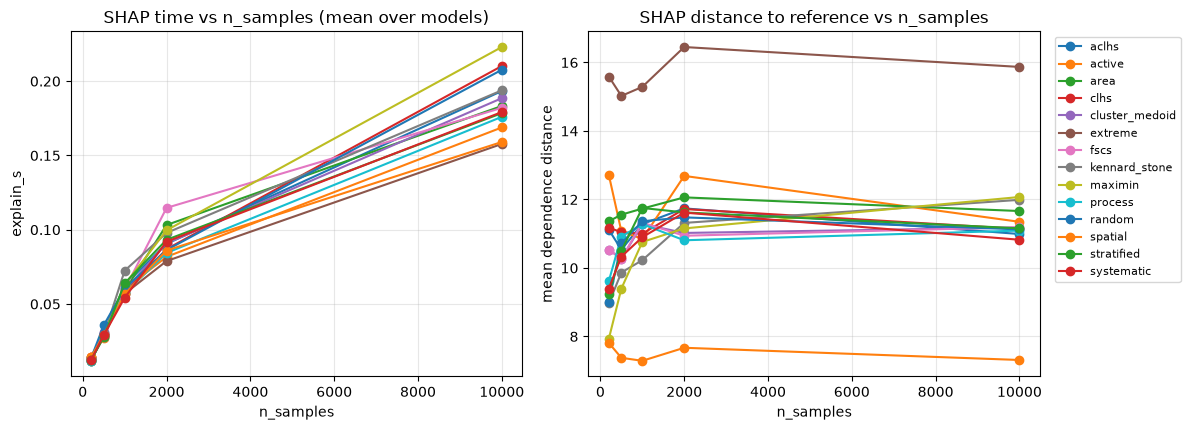

,n_samples,method,model,r2,explain_s,shap_distance,explain_method
0,200,random,extra_trees,0.718317,0.020504,0.177140,fasttreeshap
1,200,random,rf,0.683511,0.011441,0.288294,fasttreeshap
2,200,random,hist_gbm,0.712048,0.009764,0.171143,fasttreeshap
3,200,random,xgboost,0.616682,NaN,NaN,NaN
4,200,random,lightgbm,0.714156,0.014787,0.174604,fasttreeshap
...,...,...,...,...,...,...,...
415,10000,active,rf,0.782778,0.333125,0.260551,fasttreeshap
416,10000,active,hist_gbm,0.783586,0.035116,0.262023,fasttreeshap
417,10000,active,xgboost,0.786266,NaN,NaN,NaN
418,10000,active,lightgbm,0.784476,0.061470,0.265656,fasttreeshap


In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for method, group in shap_skill.groupby("method"):
    mean_t = group.groupby("n_samples")["explain_s"].mean()
    mean_d = group.groupby("n_samples")["shap_distance"].mean()
    axes[0].plot(mean_t.index, mean_t.values, marker="o", label=method)
    axes[1].plot(mean_d.index, mean_d.values, marker="o", label=method)
axes[0].set_title("SHAP time vs n_samples (mean over models)")
axes[0].set_xlabel("n_samples")
axes[0].set_ylabel("explain_s")
axes[1].set_title("SHAP distance to reference vs n_samples")
axes[1].set_xlabel("n_samples")
axes[1].set_ylabel("mean dependence distance")
for ax in axes:
    ax.grid(True, alpha=0.3)
axes[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
fig.tight_layout()
plt.show()

combo = skill.merge(shap_skill, on=["n_samples", "method", "model"], how="left")
display(combo[["n_samples", "method", "model", "r2", "explain_s", "shap_distance", "explain_method"]])